In [1]:
# ============================================================
# SHOPSMART RETAIL LTD.
# WEEK 1 - FOUNDATIONS OF MACHINE LEARNING
# ============================================================

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Regression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Classification
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Model persistence
import joblib

# Other utilities
import os
import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


# Part 1 — Machine Learning Fundamentals

## What is Machine Learning?

Machine learning is a branch of artificial intelligence that enables computer
systems to learn patterns from data and use those patterns to make predictions
or decisions without being explicitly programmed for every situation.

## Types of Machine Learning

The main types of machine learning are:

1. Supervised Learning
2. Unsupervised Learning
3. Reinforcement Learning

### Supervised Learning

Supervised learning involves training a model using data for which the target
or outcome is already known. The model learns the relationship between input
features and the target variable.

Examples include regression and classification.

### Unsupervised Learning

Unsupervised learning uses data without a predefined target variable. The
objective is to identify patterns, structures, or groups within the data.

Examples include clustering and dimensionality reduction.

### Reinforcement Learning

Reinforcement learning involves an agent learning how to make decisions by
interacting with an environment. The agent receives rewards or penalties and
learns actions that maximize its cumulative reward.

## Regression vs Classification

Regression is used when the target variable is continuous. In this project,
predicting Order_Total is a regression problem.

Classification is used when the target variable represents categories. In
this project, predicting whether an order will be returned is a binary
classification problem.

## Machine Learning Workflow

A typical machine learning workflow consists of:

1. Define the business problem
2. Collect data
3. Explore and understand the data
4. Clean and prepare the data
5. Engineer relevant features
6. Split data into training and testing sets
7. Train a model
8. Evaluate model performance
9. Interpret the model
10. Save and deploy the model
11. Monitor and improve the model

In [2]:
# ============================================================
# PART 2 - DATA PREPARATION
# ============================================================

# Load datasets

customers = pd.read_csv("ALA_ShopSmart_Customers.csv")
products = pd.read_csv("ShopSmart_Products.csv")
orders = pd.read_csv("ShopSmart_Orders.csv")
stores = pd.read_csv("ShopSmart_Stores.csv")
returns = pd.read_csv("ShopSmart_Returns.csv")
employees = pd.read_csv("ShopSmart_Employees.csv")
suppliers = pd.read_csv("ShopSmart_Suppliers.csv")
inventory = pd.read_csv("ShopSmart_Inventory.csv")
order_items = pd.read_csv("ShopSmart_Order_Items.csv")
data_dictionary = pd.read_csv("ShopSmart_Data_Dictionary.csv")

print("All datasets loaded successfully.")

All datasets loaded successfully.


In [3]:
datasets = {
    "Customers": customers,
    "Products": products,
    "Orders": orders,
    "Stores": stores,
    "Returns": returns,
    "Employees": employees,
    "Suppliers": suppliers,
    "Inventory": inventory,
    "Order Items": order_items
}

for name, df in datasets.items():
    print(f"{name:15} -> {df.shape[0]:,} rows x {df.shape[1]} columns")

Customers       -> 5,000 rows x 11 columns
Products        -> 500 rows x 7 columns
Orders          -> 50,000 rows x 12 columns
Stores          -> 25 rows x 6 columns
Returns         -> 2,500 rows x 5 columns
Employees       -> 125 rows x 6 columns
Suppliers       -> 489 rows x 6 columns
Inventory       -> 500 rows x 6 columns
Order Items     -> 50,000 rows x 7 columns


In [4]:
for name, df in datasets.items():
    print("\n" + "=" * 80)
    print(name.upper())
    print("=" * 80)

    print("\nFirst 5 rows:")
    display(df.head())

    print("\nData types:")
    print(df.dtypes)

    print("\nMissing values:")
    print(df.isnull().sum())


CUSTOMERS

First 5 rows:


,Customer_ID,First_Name,Last_Name,Gender,Age,Email,Phone,City,State,Registration_Date,Customer_Segment
0,CUST00001,Michelle,Russell,Male,65,elizabethfox@example.net,(701)981-5738x907,Abuja,Abuja,10/9/2023,Bronze
1,CUST00002,Sarah,Yu,Male,65,tfleming@example.com,6314323702,Kano,Kano,4/15/2023,Gold
2,CUST00003,Elizabeth,Adkins,Male,55,petertaylor@example.com,001-454-212-5805x0434,Asaba,Delta,3/8/2024,Bronze
3,CUST00004,Nicholas,Marshall,Male,31,kbean@example.net,001-513-728-5958x132,Lagos,Lagos,8/27/2023,Gold
4,CUST00005,Melinda,Patton,Male,53,mikaylajames@example.com,652-819-2186,Awka,Anambra,7/23/2023,Gold



Data types:
Customer_ID          object
First_Name           object
Last_Name            object
Gender               object
Age                   int64
Email                object
Phone                object
City                 object
State                object
Registration_Date    object
Customer_Segment     object
dtype: object

Missing values:
Customer_ID          0
First_Name           0
Last_Name            0
Gender               0
Age                  0
Email                0
Phone                0
City                 0
State                0
Registration_Date    0
Customer_Segment     0
dtype: int64

PRODUCTS

First 5 rows:


,Product_ID,Product_Name,Category,Sub_Category,Brand,Cost_Price,Selling_Price
0,PROD0001,Beauty Item 1,Beauty,General,Zuniga PLC,44803,75526.21
1,PROD0002,Beauty Item 2,Beauty,General,Olson-Rosales,11728,14100.26
2,PROD0003,Electronics Item 3,Electronics,General,"Mosley, Watson and Middleton",39383,52368.82
3,PROD0004,Home Item 4,Home,General,Wood Ltd,8908,13574.07
4,PROD0005,Home Item 5,Home,General,Padilla-Blake,47918,84078.14



Data types:
Product_ID        object
Product_Name      object
Category          object
Sub_Category      object
Brand             object
Cost_Price         int64
Selling_Price    float64
dtype: object

Missing values:
Product_ID       0
Product_Name     0
Category         0
Sub_Category     0
Brand            0
Cost_Price       0
Selling_Price    0
dtype: int64

ORDERS

First 5 rows:


...


Data types:
Supplier_ID      object
Supplier_Name    object
Email            object
Phone            object
City             object
Country          object
dtype: object

Missing values:
Supplier_ID      0
Supplier_Name    0
Email            0
Phone            0
City             0
Country          0
dtype: int64

INVENTORY

First 5 rows:


,Inventory_ID,Product_ID,Store_ID,Stock_On_Hand,Reorder_Level,Last_Restock_Date
0,INV00001,PROD0001,STR002,94,26,8/16/2026
1,INV00002,PROD0002,STR021,338,17,8/27/2026
2,INV00003,PROD0003,STR007,178,27,9/26/2026
3,INV00004,PROD0004,STR004,482,38,8/30/2026
4,INV00005,PROD0005,STR015,76,16,9/21/2026



Data types:
Inventory_ID         object
Product_ID           object
Store_ID             object
Stock_On_Hand         int64
Reorder_Level         int64
Last_Restock_Date    object
dtype: object

Missing values:
Inventory_ID         0
Product_ID           0
Store_ID             0
Stock_On_Hand        0
Reorder_Level        0
Last_Restock_Date    0
dtype: int64

ORDER ITEMS

First 5 rows:


,Order_Item_ID,Order_ID,Product_ID,Quantity,Unit_Price,Discount,Line_Total
0,OI000001,ORD000001,PROD0244,1,77989,10,77979
1,OI000002,ORD000002,PROD0432,3,11240,5,33715
2,OI000003,ORD000003,PROD0052,2,23595,20,47170
3,OI000004,ORD000004,PROD0051,4,69922,5,279683
4,OI000005,ORD000005,PROD0356,5,53344,0,266720



Data types:
Order_Item_ID    object
Order_ID         object
Product_ID       object
Quantity          int64
Unit_Price        int64
Discount          int64
Line_Total        int64
dtype: object

Missing values:
Order_Item_ID    0
Order_ID         0
Product_ID       0
Quantity         0
Unit_Price       0
Discount         0
Line_Total       0
dtype: int64


In [5]:
display(data_dictionary)

,Dataset,Column,Description
0,Customers,Customer_ID,Customer_ID field
1,Customers,First_Name,First_Name field
2,Customers,Last_Name,Last_Name field
3,Customers,Gender,Gender field
4,Customers,Age,Age field
5,Customers,Email,Email field
6,Customers,Phone,Phone field
7,Customers,City,City field
8,Customers,State,State field
9,Customers,Registration_Date,Registration_Date field


In [6]:
customers = customers.drop_duplicates()
products = products.drop_duplicates()
orders = orders.drop_duplicates()
stores = stores.drop_duplicates()
returns = returns.drop_duplicates()
employees = employees.drop_duplicates()
suppliers = suppliers.drop_duplicates()
inventory = inventory.drop_duplicates()
order_items = order_items.drop_duplicates()

In [7]:
def missing_values_table(df):
    missing = pd.DataFrame({
        "Missing_Count": df.isnull().sum(),
        "Missing_Percent": (df.isnull().sum() / len(df)) * 100
    })

    return missing[missing["Missing_Count"] > 0].sort_values(
        "Missing_Percent",
        ascending=False
    )


for name, df in datasets.items():

    print("\n", name.upper())

    result = missing_values_table(df)

    if result.empty:
        print("No missing values.")
    else:
        display(result)


 CUSTOMERS
No missing values.

 PRODUCTS
No missing values.

 ORDERS
No missing values.

 STORES
No missing values.

 RETURNS
No missing values.

 EMPLOYEES
No missing values.

 SUPPLIERS
No missing values.

 INVENTORY
No missing values.

 ORDER ITEMS
No missing values.


In [8]:
customers["Registration_Date"] = pd.to_datetime(
    customers["Registration_Date"],
    errors="coerce"
)

orders["Order_Date"] = pd.to_datetime(
    orders["Order_Date"],
    errors="coerce"
)

stores["Opening_Date"] = pd.to_datetime(
    stores["Opening_Date"],
    errors="coerce"
)

returns["Return_Date"] = pd.to_datetime(
    returns["Return_Date"],
    errors="coerce"
)

employees["Hire_Date"] = pd.to_datetime(
    employees["Hire_Date"],
    errors="coerce"
)

inventory["Last_Restock_Date"] = pd.to_datetime(
    inventory["Last_Restock_Date"],
    errors="coerce"
)

print("Date columns converted successfully.")

Date columns converted successfully.


In [11]:
orders

,Order_ID,Customer_ID,Product_ID,Store_ID,Order_Date,Quantity,Unit_Price,Discount,Shipping_Cost,Payment_Method,Sales_Channel,Order_Status
0,ORD000001,CUST04572,PROD0244,STR005,2025-07-19,1,77989,10,3833,Card,Online,Completed
1,ORD000002,CUST04064,PROD0432,STR010,2025-03-15,3,11240,5,2872,Card,In-Store,Cancelled
2,ORD000003,CUST03435,PROD0052,STR004,2025-10-01,2,23595,20,922,Card,Online,Pending
3,ORD000004,CUST03536,PROD0051,STR023,2025-07-15,4,69922,5,911,Transfer,Online,Completed
4,ORD000005,CUST03676,PROD0356,STR021,2025-03-28,5,53344,0,1740,Card,Online,Cancelled
...,...,...,...,...,...,...,...,...,...,...,...,...
49995,ORD049996,CUST02444,PROD0285,STR007,2025-06-20,3,83400,0,3807,Transfer,Online,Cancelled
49996,ORD049997,CUST02331,PROD0116,STR010,2025-12-28,4,23590,5,2735,Cash,In-Store,Completed
49997,ORD049998,CUST03580,PROD0252,STR004,2025-01-20,3,43552,10,2852,Transfer,Online,Pending
49998,ORD049999,CUST04995,PROD0369,STR002,2025-07-16,4,5307,20,1811,Card,Online,Cancelled


In [12]:
orders["Order_Total"] = (
    orders["Quantity"] * orders["Unit_Price"]
    - orders["Discount"]
    + orders["Shipping_Cost"]
)

orders[
    [
        "Order_ID",
        "Quantity",
        "Unit_Price",
        "Discount",
        "Shipping_Cost",
        "Order_Total"
    ]
].head()

,Order_ID,Quantity,Unit_Price,Discount,Shipping_Cost,Order_Total
0,ORD000001,1,77989,10,3833,81812
1,ORD000002,3,11240,5,2872,36587
2,ORD000003,2,23595,20,922,48092
3,ORD000004,4,69922,5,911,280594
4,ORD000005,5,53344,0,1740,268460


In [13]:
returned_orders = set(returns["Order_ID"])

orders["Return_Flag"] = (
    orders["Order_ID"]
    .isin(returned_orders)
    .astype(int)
)

orders["Return_Flag"].value_counts()

Return_Flag
0    47558
1     2442
Name: count, dtype: int64

In [14]:
print(
    orders["Return_Flag"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Return_Flag
0    95.12
1     4.88
Name: proportion, dtype: float64


In [19]:
employee_summary = (
    employees
    .groupby("Store_ID")
    .agg(
        Employee_Count=("Employee_ID", "count"),
        Average_Employee_Salary=("Monthly_Salary", "mean")
    )
    .reset_index()
)

employee_summary.head()

,Store_ID,Employee_Count,Average_Employee_Salary
0,STR001,5,3717.4
1,STR002,5,4280.4
2,STR003,5,3077.2
3,STR004,5,3752.4
4,STR005,5,2299.8


In [20]:
inventory_summary = (
    inventory
    .groupby(["Product_ID", "Store_ID"])
    .agg(
        Stock_On_Hand=("Stock_On_Hand", "mean"),
        Reorder_Level=("Reorder_Level", "mean")
    )
    .reset_index()
)

inventory_summary.head()

,Product_ID,Store_ID,Stock_On_Hand,Reorder_Level
0,PROD0001,STR002,94.0,26.0
1,PROD0002,STR021,338.0,17.0
2,PROD0003,STR007,178.0,27.0
3,PROD0004,STR004,482.0,38.0
4,PROD0005,STR015,76.0,16.0


In [32]:
# ============================================================
# MASTER DATASET
# ============================================================

master = orders.copy()

print("Starting Orders:", len(master))


# ------------------------------------------------------------
# Merge Customers
# ------------------------------------------------------------

master = master.merge(
    customers,
    on="Customer_ID",
    how="left",
    suffixes=("", "_Customer"),
    validate="many_to_one"
)

print("After Customers:", len(master))


# ------------------------------------------------------------
# Merge Products
# ------------------------------------------------------------

master = master.merge(
    products,
    on="Product_ID",
    how="left",
    validate="many_to_one"
)

print("After Products:", len(master))


# ------------------------------------------------------------
# Merge Stores
# ------------------------------------------------------------

master = master.merge(
    stores,
    on="Store_ID",
    how="left",
    suffixes=("_Customer", "_Store"),
    validate="many_to_one"
)

print("After Stores:", len(master))


# ------------------------------------------------------------
# Merge Returns Summary
# ------------------------------------------------------------

master = master.merge(
    returns_summary,
    on="Order_ID",
    how="left",
    validate="one_to_one"
)

print("After Returns:", len(master))


# ------------------------------------------------------------
# Merge Employee Summary
# ------------------------------------------------------------

master = master.merge(
    employee_summary,
    on="Store_ID",
    how="left",
    validate="many_to_one"
)

print("After Employee Summary:", len(master))


# ------------------------------------------------------------
# Merge Inventory Summary
# ------------------------------------------------------------

master = master.merge(
    inventory_summary,
    on=["Product_ID", "Store_ID"],
    how="left",
    validate="many_to_one"
)

print("After Inventory Summary:", len(master))

Starting Orders: 50000
After Customers: 50000
After Products: 50000
After Stores: 50000
After Returns: 50000
After Employee Summary: 50000
After Inventory Summary: 50000


### Supplier Dataset

The supplier dataset was reviewed during data preparation. However, it does
not contain a Product_ID or another reliable key connecting individual
suppliers to the transactions in the Orders dataset. Therefore, it was not
merged into the order-level master dataset because doing so would require an
unsupported assumption about which supplier provided each product.

In [38]:
print("Master dataset shape:", master.shape)

print("\nColumns in master dataset:")
print(master.columns.tolist())

Master dataset shape: (50000, 50)

Columns in master dataset:
['Order_ID', 'Customer_ID', 'Product_ID', 'Store_ID', 'Order_Date', 'Quantity', 'Unit_Price', 'Discount', 'Shipping_Cost', 'Payment_Method', 'Sales_Channel', 'Order_Status', 'Order_Total', 'Return_Flag', 'First_Name', 'Last_Name', 'Gender', 'Age', 'Email', 'Phone', 'City_Customer', 'State_Customer', 'Registration_Date', 'Customer_Segment', 'Product_Name', 'Category', 'Sub_Category', 'Brand', 'Cost_Price', 'Selling_Price', 'Store_Name', 'Region', 'State_Store', 'City_Store', 'Opening_Date', 'Return_Count', 'Total_Refund_Amount', 'Latest_Return_Date', 'Return_Reason', 'Employee_Count', 'Average_Employee_Salary', 'Stock_On_Hand', 'Reorder_Level', 'Order_Year', 'Order_Month', 'Order_DayOfWeek', 'Order_Quarter', 'Customer_Tenure_Days', 'Store_Age_Days', 'Estimated_Unit_Margin']


In [39]:
# ============================================================
# FEATURE ENGINEERING
# ============================================================

# Make sure date columns are datetime
master["Order_Date"] = pd.to_datetime(
    master["Order_Date"],
    errors="coerce"
)

master["Registration_Date"] = pd.to_datetime(
    master["Registration_Date"],
    errors="coerce"
)

master["Opening_Date"] = pd.to_datetime(
    master["Opening_Date"],
    errors="coerce"
)

master["Latest_Return_Date"] = pd.to_datetime(
    master["Latest_Return_Date"],
    errors="coerce"
)


# ------------------------------------------------------------
# Order date features
# ------------------------------------------------------------

master["Order_Year"] = master["Order_Date"].dt.year

master["Order_Month"] = master["Order_Date"].dt.month

master["Order_DayOfWeek"] = master["Order_Date"].dt.dayofweek

master["Order_Quarter"] = master["Order_Date"].dt.quarter


# ------------------------------------------------------------
# Customer tenure
# ------------------------------------------------------------

master["Customer_Tenure_Days"] = (
    master["Order_Date"] -
    master["Registration_Date"]
).dt.days


# ------------------------------------------------------------
# Store age
# ------------------------------------------------------------

master["Store_Age_Days"] = (
    master["Order_Date"] -
    master["Opening_Date"]
).dt.days


# ------------------------------------------------------------
# Estimated unit margin
# ------------------------------------------------------------

master["Estimated_Unit_Margin"] = (
    master["Unit_Price"] -
    master["Cost_Price"]
)


print("Feature engineering completed successfully.")

display(
    master[
        [
            "Order_ID",
            "Order_Year",
            "Order_Month",
            "Order_DayOfWeek",
            "Order_Quarter",
            "Customer_Tenure_Days",
            "Store_Age_Days",
            "Estimated_Unit_Margin"
        ]
    ].head()
)

Feature engineering completed successfully.


,Order_ID,Order_Year,Order_Month,Order_DayOfWeek,Order_Quarter,Customer_Tenure_Days,Store_Age_Days,Estimated_Unit_Margin
0,ORD000001,2025,7,5,3,791,1876,29358
1,ORD000002,2025,3,5,1,341,1600,7971
2,ORD000003,2025,10,2,4,26,1980,-7432
3,ORD000004,2025,7,1,3,222,1332,40708
4,ORD000005,2025,3,4,1,148,1283,18120


In [40]:
# ============================================================
# MISSING VALUE CHECK
# ============================================================

missing = pd.DataFrame({
    "Missing_Count": master.isnull().sum(),
    "Missing_Percent": (
        master.isnull().mean() * 100
    )
})

missing = missing[
    missing["Missing_Count"] > 0
].sort_values(
    "Missing_Percent",
    ascending=False
)

display(missing)

,Missing_Count,Missing_Percent
Stock_On_Hand,48000,96.000
Reorder_Level,48000,96.000
Latest_Return_Date,47558,95.116


In [41]:
# ------------------------------------------------------------
# Return-related missing values
# ------------------------------------------------------------

master["Total_Refund_Amount"] = (
    master["Total_Refund_Amount"]
    .fillna(0)
)

master["Return_Count"] = (
    master["Return_Count"]
    .fillna(0)
)

master["Return_Reason"] = (
    master["Return_Reason"]
    .fillna("Not Returned")
)

In [42]:
# ------------------------------------------------------------
# Inventory-related missing values
# ------------------------------------------------------------

master["Stock_On_Hand"] = (
    master["Stock_On_Hand"]
    .fillna(
        master["Stock_On_Hand"].median()
    )
)

master["Reorder_Level"] = (
    master["Reorder_Level"]
    .fillna(
        master["Reorder_Level"].median()
    )
)

In [43]:
missing_after = pd.DataFrame({
    "Missing_Count": master.isnull().sum(),
    "Missing_Percent": master.isnull().mean() * 100
})

missing_after = missing_after[
    missing_after["Missing_Count"] > 0
].sort_values(
    "Missing_Percent",
    ascending=False
)

display(missing_after)

,Missing_Count,Missing_Percent
Latest_Return_Date,47558,95.116


In [44]:
print("=" * 60)
print("FINAL DATA QUALITY CHECK")
print("=" * 60)

print("Rows:", master.shape[0])
print("Columns:", master.shape[1])

print(
    "Unique Order IDs:",
    master["Order_ID"].nunique()
)

print(
    "Duplicate Order IDs:",
    master["Order_ID"].duplicated().sum()
)

print(
    "Returned orders:",
    master["Return_Flag"].sum()
)

print(
    "Return rate:",
    f"{master['Return_Flag'].mean():.2%}"
)

FINAL DATA QUALITY CHECK
Rows: 50000
Columns: 50
Unique Order IDs: 50000
Duplicate Order IDs: 0
Returned orders: 2442
Return rate: 4.88%


In [45]:
# ============================================================
# SAVE MASTER DATASET
# ============================================================

import os

os.makedirs("data", exist_ok=True)

master.to_csv(
    "data/master_dataset.csv",
    index=False
)

print("Master dataset saved successfully.")

Master dataset saved successfully.


In [46]:
# ============================================================
# PART 3 - LINEAR REGRESSION
# ============================================================

regression_features = [
    "Age",
    "Customer_Segment",
    "Category",
    "Brand",
    "Store_ID",
    "Region",
    "Payment_Method",
    "Sales_Channel",
    "Quantity",
    "Unit_Price",
    "Discount",
    "Shipping_Cost",
    "Order_Month",
    "Order_DayOfWeek"
]

target_reg = "Order_Total"


X_reg = master[
    regression_features
].copy()

y_reg = master[
    target_reg
].copy()


print("Regression features shape:", X_reg.shape)
print("Regression target shape:", y_reg.shape)

display(X_reg.head())

Regression features shape: (50000, 14)
Regression target shape: (50000,)


,Age,Customer_Segment,Category,Brand,Store_ID,Region,Payment_Method,Sales_Channel,Quantity,Unit_Price,Discount,Shipping_Cost,Order_Month,Order_DayOfWeek
0,69,Silver,Groceries,Olson-Vance,STR005,South,Card,Online,1,77989,10,3833,7,5
1,66,Gold,Home,Jones-Vaughn,STR010,North,Card,In-Store,3,11240,5,2872,3,5
2,22,Bronze,Electronics,"Martinez, Rice and Perry",STR004,South,Card,Online,2,23595,20,922,10,2
3,55,Silver,Home,"Peterson, Berry and Cook",STR023,South,Transfer,Online,4,69922,5,911,7,1
4,44,Bronze,Electronics,"Sanders, Flores and Lopez",STR021,West,Card,Online,5,53344,0,1740,3,4


In [47]:
numerical_features_reg = [
    "Age",
    "Quantity",
    "Unit_Price",
    "Discount",
    "Shipping_Cost",
    "Order_Month",
    "Order_DayOfWeek"
]


categorical_features_reg = [
    "Customer_Segment",
    "Category",
    "Brand",
    "Store_ID",
    "Region",
    "Payment_Method",
    "Sales_Channel"
]


print(
    "Numerical features:",
    numerical_features_reg
)

print(
    "\nCategorical features:",
    categorical_features_reg
)

Numerical features: ['Age', 'Quantity', 'Unit_Price', 'Discount', 'Shipping_Cost', 'Order_Month', 'Order_DayOfWeek']

Categorical features: ['Customer_Segment', 'Category', 'Brand', 'Store_ID', 'Region', 'Payment_Method', 'Sales_Channel']


In [48]:
from sklearn.model_selection import train_test_split


X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg,
    y_reg,
    test_size=0.20,
    random_state=42
)


print(
    "Training observations:",
    X_train_reg.shape[0]
)

print(
    "Testing observations:",
    X_test_reg.shape[0]
)

Training observations: 40000
Testing observations: 10000


In [49]:
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.compose import ColumnTransformer


reg_preprocessor = ColumnTransformer(
    transformers=[
        
        (
            "num",
            StandardScaler(),
            numerical_features_reg
        ),

        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            ),
            categorical_features_reg
        )
    ]
)


print("Regression preprocessor created.")

Regression preprocessor created.


In [50]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression


linear_model = Pipeline(
    steps=[
        
        (
            "preprocessor",
            reg_preprocessor
        ),

        (
            "model",
            LinearRegression()
        )
    ]
)


print("Linear Regression pipeline created.")

Linear Regression pipeline created.


In [51]:
linear_model.fit(
    X_train_reg,
    y_train_reg
)

print(
    "Linear Regression model trained successfully."
)

Linear Regression model trained successfully.


In [52]:
y_pred_reg = linear_model.predict(
    X_test_reg
)

print("First 10 predictions:")

print(
    y_pred_reg[:10]
)

First 10 predictions:
[180292.83348777 368134.7784633  124885.37549041 187047.64197188
  21695.22323689 192264.9721338  128106.7078345   -5329.29971058
 255037.73538409  26806.61860167]


In [53]:
regression_results = pd.DataFrame({
    "Actual": y_test_reg.values,
    "Predicted": y_pred_reg
})

regression_results["Error"] = (
    regression_results["Actual"] -
    regression_results["Predicted"]
)

regression_results["Absolute_Error"] = (
    regression_results["Error"].abs()
)

display(regression_results.head(10))

,Actual,Predicted,Error,Absolute_Error
0,166896,180292.833488,-13396.833488,13396.833488
1,427532,368134.778463,59397.221537,59397.221537
2,124876,124885.375490,-9.375490,9.375490
3,97203,187047.641972,-89844.641972,89844.641972
4,48255,21695.223237,26559.776763,26559.776763
5,194977,192264.972134,2712.027866,2712.027866
6,126150,128106.707835,-1956.707835,1956.707835
7,26751,-5329.299711,32080.299711,32080.299711
8,253611,255037.735384,-1426.735384,1426.735384
9,47592,26806.618602,20785.381398,20785.381398


In [54]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


mae = mean_absolute_error(
    y_test_reg,
    y_pred_reg
)


rmse = np.sqrt(
    mean_squared_error(
        y_test_reg,
        y_pred_reg
    )
)


r2 = r2_score(
    y_test_reg,
    y_pred_reg
)


print("=" * 50)
print("LINEAR REGRESSION PERFORMANCE")
print("=" * 50)

print(f"MAE  : {mae:,.2f}")
print(f"RMSE : {rmse:,.2f}")
print(f"R²   : {r2:.4f}")

LINEAR REGRESSION PERFORMANCE
MAE  : 31,010.22
RMSE : 41,268.26
R²   : 0.8830


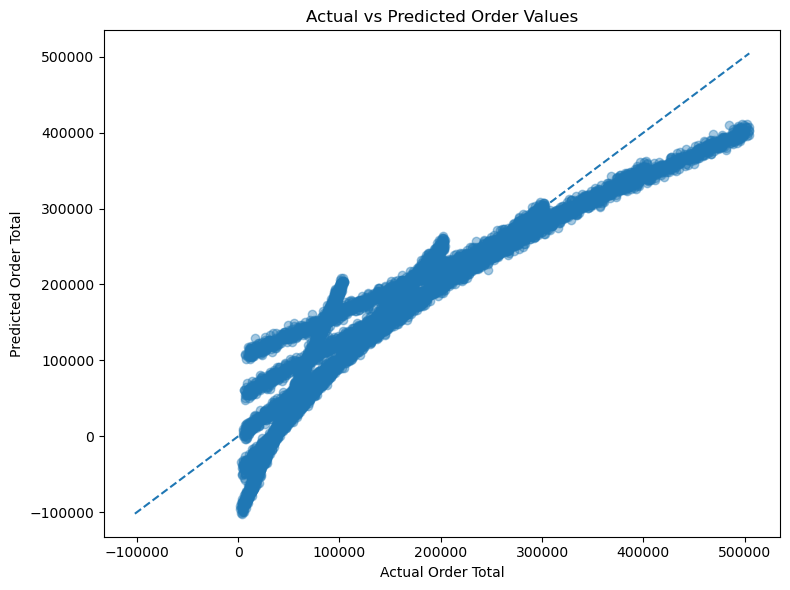

In [55]:
plt.figure(
    figsize=(8, 6)
)

plt.scatter(
    y_test_reg,
    y_pred_reg,
    alpha=0.4
)


minimum = min(
    y_test_reg.min(),
    y_pred_reg.min()
)

maximum = max(
    y_test_reg.max(),
    y_pred_reg.max()
)


plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)


plt.xlabel(
    "Actual Order Total"
)

plt.ylabel(
    "Predicted Order Total"
)

plt.title(
    "Actual vs Predicted Order Values"
)

plt.tight_layout()

plt.show()

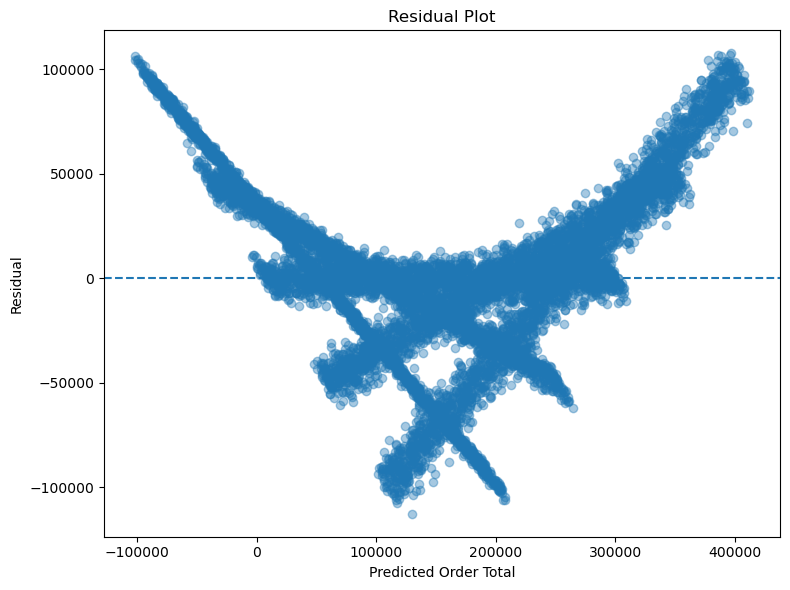

In [56]:
residuals = (
    y_test_reg -
    y_pred_reg
)


plt.figure(
    figsize=(8, 6)
)


plt.scatter(
    y_pred_reg,
    residuals,
    alpha=0.4
)


plt.axhline(
    y=0,
    linestyle="--"
)


plt.xlabel(
    "Predicted Order Total"
)

plt.ylabel(
    "Residual"
)

plt.title(
    "Residual Plot"
)


plt.tight_layout()

plt.show()

In [57]:
# ============================================================
# PART 4 - LOGISTIC REGRESSION
# ============================================================

classification_features = [
    "Age",
    "Customer_Segment",
    "Category",
    "Brand",
    "Store_ID",
    "Region",
    "Payment_Method",
    "Sales_Channel",
    "Order_Status",
    "Quantity",
    "Unit_Price",
    "Discount",
    "Shipping_Cost",
    "Order_Total",
    "Order_Month",
    "Order_DayOfWeek"
]


target_class = "Return_Flag"


X_class = master[
    classification_features
].copy()

y_class = master[
    target_class
].copy()


print(
    "Classification features shape:",
    X_class.shape
)

print(
    "Classification target shape:",
    y_class.shape
)

Classification features shape: (50000, 16)
Classification target shape: (50000,)


In [58]:
print(
    "Return Flag counts:"
)

print(
    y_class.value_counts()
)


print(
    "\nReturn Flag percentages:"
)

print(
    y_class
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Return Flag counts:
Return_Flag
0    47558
1     2442
Name: count, dtype: int64

Return Flag percentages:
Return_Flag
0    95.12
1     4.88
Name: proportion, dtype: float64


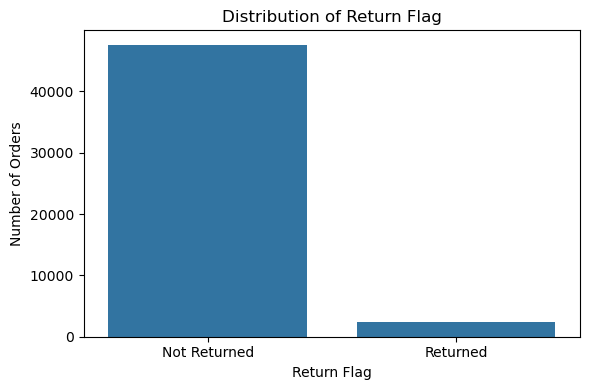

In [59]:
plt.figure(
    figsize=(6, 4)
)

sns.countplot(
    x=y_class
)

plt.title(
    "Distribution of Return Flag"
)

plt.xlabel(
    "Return Flag"
)

plt.ylabel(
    "Number of Orders"
)

plt.xticks(
    [0, 1],
    ["Not Returned", "Returned"]
)

plt.tight_layout()

plt.show()

In [60]:
numerical_features_class = [
    "Age",
    "Quantity",
    "Unit_Price",
    "Discount",
    "Shipping_Cost",
    "Order_Total",
    "Order_Month",
    "Order_DayOfWeek"
]


categorical_features_class = [
    "Customer_Segment",
    "Category",
    "Brand",
    "Store_ID",
    "Region",
    "Payment_Method",
    "Sales_Channel",
    "Order_Status"
]

In [61]:
X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    X_class,
    y_class,
    test_size=0.20,
    random_state=42,
    stratify=y_class
)


print(
    "Training observations:",
    X_train_class.shape[0]
)

print(
    "Testing observations:",
    X_test_class.shape[0]
)


print(
    "\nTraining class distribution:"
)

print(
    y_train_class
    .value_counts(normalize=True)
    .round(4)
)


print(
    "\nTesting class distribution:"
)

print(
    y_test_class
    .value_counts(normalize=True)
    .round(4)
)

Training observations: 40000
Testing observations: 10000

Training class distribution:
Return_Flag
0    0.9512
1    0.0488
Name: proportion, dtype: float64

Testing class distribution:
Return_Flag
0    0.9512
1    0.0488
Name: proportion, dtype: float64


In [62]:
class_preprocessor = ColumnTransformer(
    transformers=[
        
        (
            "num",
            StandardScaler(),
            numerical_features_class
        ),

        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            ),
            categorical_features_class
        )
    ]
)


print(
    "Classification preprocessor created."
)

Classification preprocessor created.


In [63]:
from sklearn.linear_model import LogisticRegression


logistic_model = Pipeline(
    steps=[
        
        (
            "preprocessor",
            class_preprocessor
        ),

        (
            "model",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)


print(
    "Logistic Regression pipeline created."
)

Logistic Regression pipeline created.


In [64]:
logistic_model.fit(
    X_train_class,
    y_train_class
)


print(
    "Logistic Regression model trained successfully."
)

Logistic Regression model trained successfully.


In [65]:
y_pred_class = logistic_model.predict(
    X_test_class
)


y_prob_class = logistic_model.predict_proba(
    X_test_class
)[:, 1]


classification_results = pd.DataFrame({
    "Actual_Return": y_test_class.values,
    "Predicted_Return": y_pred_class,
    "Return_Probability": y_prob_class
})


display(
    classification_results.head(10)
)

,Actual_Return,Predicted_Return,Return_Probability
0,0,0,0.331491
1,0,0,0.375225
2,0,1,0.571607
3,0,0,0.365926
4,0,0,0.216324
5,0,0,0.479166
6,0,1,0.559300
7,0,0,0.279811
8,0,1,0.572333
9,0,0,0.318630


In [66]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


accuracy = accuracy_score(
    y_test_class,
    y_pred_class
)


precision = precision_score(
    y_test_class,
    y_pred_class,
    zero_division=0
)


recall = recall_score(
    y_test_class,
    y_pred_class,
    zero_division=0
)


f1 = f1_score(
    y_test_class,
    y_pred_class,
    zero_division=0
)


print("=" * 50)
print("LOGISTIC REGRESSION PERFORMANCE")
print("=" * 50)

print(
    f"Accuracy  : {accuracy:.4f}"
)

print(
    f"Precision : {precision:.4f}"
)

print(
    f"Recall    : {recall:.4f}"
)

print(
    f"F1 Score  : {f1:.4f}"
)

LOGISTIC REGRESSION PERFORMANCE
Accuracy  : 0.5430
Precision : 0.0475
Recall    : 0.4385
F1 Score  : 0.0856


In [67]:
print(
    classification_report(
        y_test_class,
        y_pred_class,
        target_names=[
            "Not Returned",
            "Returned"
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

Not Returned       0.95      0.55      0.70      9512
    Returned       0.05      0.44      0.09       488

    accuracy                           0.54     10000
   macro avg       0.50      0.49      0.39     10000
weighted avg       0.91      0.54      0.67     10000



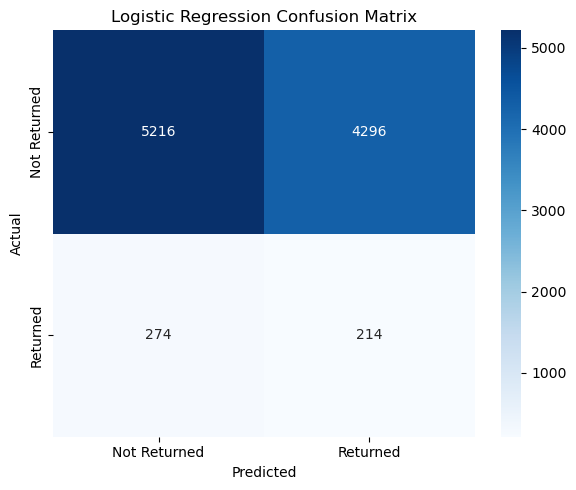

In [68]:
cm = confusion_matrix(
    y_test_class,
    y_pred_class
)


plt.figure(
    figsize=(6, 5)
)


sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Not Returned",
        "Returned"
    ],
    yticklabels=[
        "Not Returned",
        "Returned"
    ]
)


plt.xlabel(
    "Predicted"
)

plt.ylabel(
    "Actual"
)

plt.title(
    "Logistic Regression Confusion Matrix"
)


plt.tight_layout()

plt.show()

# Part 5 — Understanding Model Evaluation

## Classification Metrics

### Accuracy

Accuracy is the proportion of all observations that the model predicts
correctly. It is most informative when the classes are reasonably balanced.
However, it can be misleading for highly imbalanced datasets.

### Precision

Precision measures the proportion of observations predicted as positive that
are actually positive. In the ShopSmart problem, it answers:

"Of all orders predicted to be returned, how many were actually returned?"

Precision is particularly important when false positive predictions are costly.

### Recall

Recall measures the proportion of actual positive cases correctly identified.
For ShopSmart, it answers:

"Of all orders that were actually returned, how many did the model identify?"

Recall is important when failing to identify a positive case is costly.

### F1 Score

The F1 score combines precision and recall into a single metric. It is useful
when the classes are imbalanced and both false positives and false negatives
are important.

## Regression Metrics

### Mean Absolute Error (MAE)

MAE represents the average absolute difference between actual and predicted
values. It is expressed in the same units as the target variable and is
therefore easy to interpret.

### Root Mean Squared Error (RMSE)

RMSE measures prediction error but penalizes larger errors more heavily than
MAE. It is useful when large prediction errors are particularly undesirable.

### R-squared (R²)

R² measures the proportion of variation in the target variable explained by
the regression model. A value closer to 1 indicates that a larger proportion
of the variation in the target is explained by the model.

In [69]:
# ============================================================
# REGRESSION FEATURE IMPORTANCE
# ============================================================

reg_feature_names = (
    linear_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)


reg_coefficients = (
    linear_model
    .named_steps["model"]
    .coef_
)


reg_importance = pd.DataFrame({
    "Feature": reg_feature_names,
    "Coefficient": reg_coefficients
})


reg_importance[
    "Absolute_Coefficient"
] = (
    reg_importance[
        "Coefficient"
    ].abs()
)


reg_importance = (
    reg_importance
    .sort_values(
        "Absolute_Coefficient",
        ascending=False
    )
)


display(
    reg_importance.head(20)
)

,Feature,Coefficient,Absolute_Coefficient
2,num__Unit_Price,85388.735528,85388.735528
1,num__Quantity,71148.074287,71148.074287
244,cat__Brand_Lester Ltd,-23200.401222,23200.401222
429,cat__Brand_Suarez and Sons,-21219.151129,21219.151129
430,"cat__Brand_Sullivan, Nguyen and Young",-21180.149101,21180.149101
450,cat__Brand_Vasquez-Russell,-20822.773144,20822.773144
294,cat__Brand_Mcpherson-Fernandez,-20417.968519,20417.968519
13,cat__Brand_Adams and Sons,-20252.428380,20252.428380
421,cat__Brand_Smith-Robinson,-19817.049316,19817.049316
63,"cat__Brand_Carter, Hernandez and Schmidt",-19532.891670,19532.891670


In [70]:
reg_importance["Feature"] = (
    reg_importance["Feature"]
    .str.replace(
        "num__",
        "",
        regex=False
    )
    .str.replace(
        "cat__",
        "",
        regex=False
    )
)

display(
    reg_importance.head(20)
)

,Feature,Coefficient,Absolute_Coefficient
2,Unit_Price,85388.735528,85388.735528
1,Quantity,71148.074287,71148.074287
244,Brand_Lester Ltd,-23200.401222,23200.401222
429,Brand_Suarez and Sons,-21219.151129,21219.151129
430,"Brand_Sullivan, Nguyen and Young",-21180.149101,21180.149101
450,Brand_Vasquez-Russell,-20822.773144,20822.773144
294,Brand_Mcpherson-Fernandez,-20417.968519,20417.968519
13,Brand_Adams and Sons,-20252.428380,20252.428380
421,Brand_Smith-Robinson,-19817.049316,19817.049316
63,"Brand_Carter, Hernandez and Schmidt",-19532.891670,19532.891670


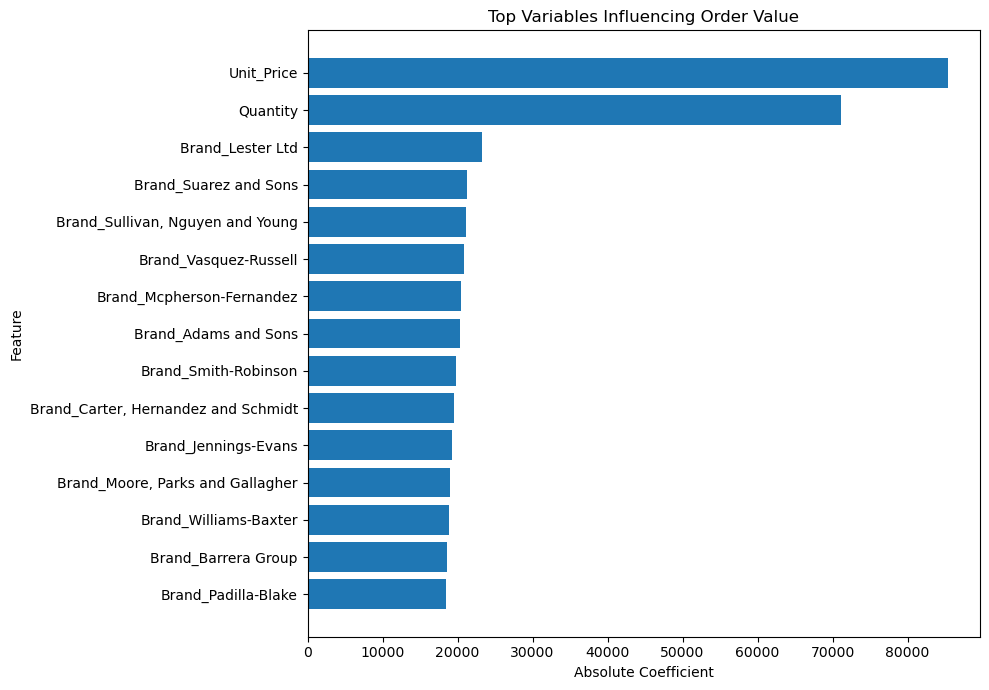

In [71]:
top_reg = (
    reg_importance
    .head(15)
    .sort_values(
        "Absolute_Coefficient"
    )
)


plt.figure(
    figsize=(10, 7)
)


plt.barh(
    top_reg["Feature"],
    top_reg["Absolute_Coefficient"]
)


plt.xlabel(
    "Absolute Coefficient"
)

plt.ylabel(
    "Feature"
)

plt.title(
    "Top Variables Influencing Order Value"
)


plt.tight_layout()

plt.show()

In [72]:
# ============================================================
# CLASSIFICATION FEATURE IMPORTANCE
# ============================================================

class_feature_names = (
    logistic_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)


class_coefficients = (
    logistic_model
    .named_steps["model"]
    .coef_[0]
)


class_importance = pd.DataFrame({
    "Feature": class_feature_names,
    "Coefficient": class_coefficients
})


class_importance[
    "Absolute_Coefficient"
] = (
    class_importance[
        "Coefficient"
    ].abs()
)


class_importance = (
    class_importance
    .sort_values(
        "Absolute_Coefficient",
        ascending=False
    )
)


class_importance["Feature"] = (
    class_importance["Feature"]
    .str.replace(
        "num__",
        "",
        regex=False
    )
    .str.replace(
        "cat__",
        "",
        regex=False
    )
)


display(
    class_importance.head(20)
)

,Feature,Coefficient,Absolute_Coefficient
148,Brand_Gentry-Ward,-2.635660,2.635660
17,"Brand_Allen, Lewis and Hoover",-2.594522,2.594522
266,"Brand_Martin, Haley and Parrish",-2.584624,2.584624
311,Brand_Mitchell-Mcdaniel,-2.523349,2.523349
421,Brand_Smith-Kline,-1.357506,1.357506
388,"Brand_Robinson, Baker and Knight",-1.306833,1.306833
492,"Brand_Wilson, Young and Ramos",-1.295823,1.295823
438,Brand_Thompson and Sons,-1.273442,1.273442
287,Brand_Mcdaniel-Torres,-1.261643,1.261643
46,Brand_Brown-Cherry,-1.250643,1.250643


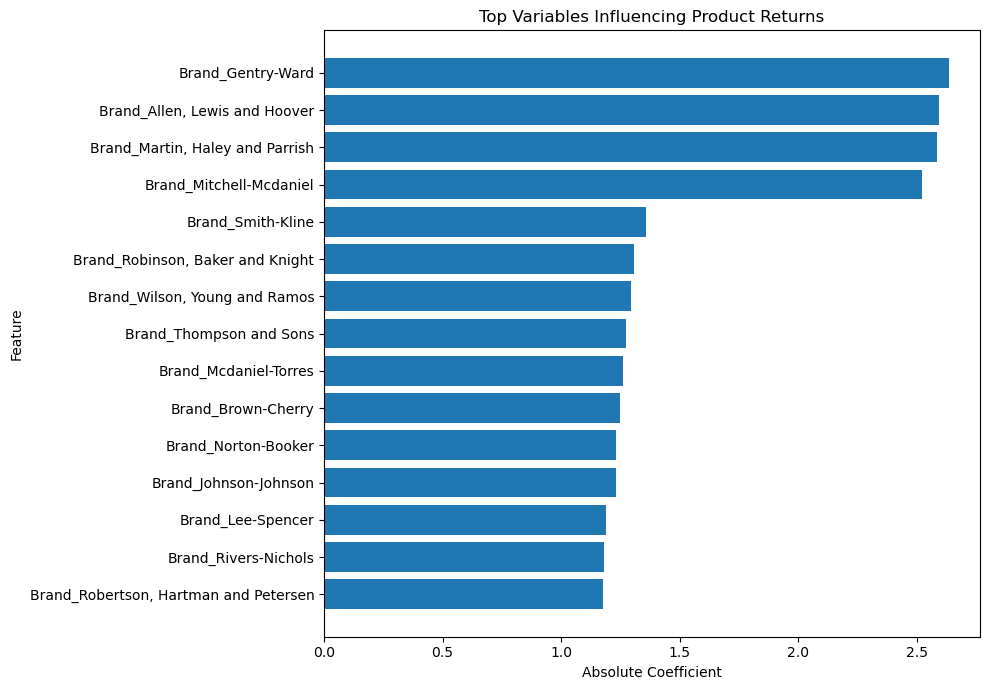

In [73]:
top_class = (
    class_importance
    .head(15)
    .sort_values(
        "Absolute_Coefficient"
    )
)


plt.figure(
    figsize=(10, 7)
)


plt.barh(
    top_class["Feature"],
    top_class["Absolute_Coefficient"]
)


plt.xlabel(
    "Absolute Coefficient"
)

plt.ylabel(
    "Feature"
)

plt.title(
    "Top Variables Influencing Product Returns"
)


plt.tight_layout()

plt.show()

In [74]:
print(
    "TOP VARIABLES PREDICTING ORDER VALUE"
)

display(
    reg_importance[
        [
            "Feature",
            "Coefficient",
            "Absolute_Coefficient"
        ]
    ].head(15)
)

TOP VARIABLES PREDICTING ORDER VALUE


,Feature,Coefficient,Absolute_Coefficient
2,Unit_Price,85388.735528,85388.735528
1,Quantity,71148.074287,71148.074287
244,Brand_Lester Ltd,-23200.401222,23200.401222
429,Brand_Suarez and Sons,-21219.151129,21219.151129
430,"Brand_Sullivan, Nguyen and Young",-21180.149101,21180.149101
450,Brand_Vasquez-Russell,-20822.773144,20822.773144
294,Brand_Mcpherson-Fernandez,-20417.968519,20417.968519
13,Brand_Adams and Sons,-20252.428380,20252.428380
421,Brand_Smith-Robinson,-19817.049316,19817.049316
63,"Brand_Carter, Hernandez and Schmidt",-19532.891670,19532.891670


In [75]:
print(
    "TOP VARIABLES INFLUENCING PRODUCT RETURNS"
)

display(
    class_importance[
        [
            "Feature",
            "Coefficient",
            "Absolute_Coefficient"
        ]
    ].head(15)
)

TOP VARIABLES INFLUENCING PRODUCT RETURNS


,Feature,Coefficient,Absolute_Coefficient
148,Brand_Gentry-Ward,-2.635660,2.635660
17,"Brand_Allen, Lewis and Hoover",-2.594522,2.594522
266,"Brand_Martin, Haley and Parrish",-2.584624,2.584624
311,Brand_Mitchell-Mcdaniel,-2.523349,2.523349
421,Brand_Smith-Kline,-1.357506,1.357506
388,"Brand_Robinson, Baker and Knight",-1.306833,1.306833
492,"Brand_Wilson, Young and Ramos",-1.295823,1.295823
438,Brand_Thompson and Sons,-1.273442,1.273442
287,Brand_Mcdaniel-Torres,-1.261643,1.261643
46,Brand_Brown-Cherry,-1.250643,1.250643


In [76]:
product_prediction_results = pd.DataFrame({
    "Product_ID": master.loc[
        X_test_reg.index,
        "Product_ID"
    ].values,

    "Product_Name": master.loc[
        X_test_reg.index,
        "Product_Name"
    ].values,

    "Actual_Order_Total": y_test_reg.values,

    "Predicted_Order_Total": y_pred_reg
})


product_prediction_results[
    "Absolute_Error"
] = abs(
    product_prediction_results[
        "Actual_Order_Total"
    ] -
    product_prediction_results[
        "Predicted_Order_Total"
    ]
)


product_prediction = (
    product_prediction_results
    .groupby(
        [
            "Product_ID",
            "Product_Name"
        ]
    )
    .agg(
        Number_of_Orders=(
            "Absolute_Error",
            "size"
        ),

        MAE=(
            "Absolute_Error",
            "mean"
        )
    )
    .reset_index()
)


# Require a minimum number of test observations
product_prediction = (
    product_prediction[
        product_prediction[
            "Number_of_Orders"
        ] >= 10
    ]
    .sort_values(
        "MAE",
        ascending=True
    )
)


display(
    product_prediction.head(10)
)

,Product_ID,Product_Name,Number_of_Orders,MAE
188,PROD0189,Beauty Item 189,16,16456.722164
380,PROD0381,Fashion Item 381,16,16540.293084
394,PROD0395,Fashion Item 395,17,17323.242709
498,PROD0499,Fashion Item 499,21,17826.982257
9,PROD0010,Beauty Item 10,14,18148.354505
492,PROD0493,Groceries Item 493,15,18384.357287
54,PROD0055,Beauty Item 55,13,18570.281174
470,PROD0471,Home Item 471,20,19057.234905
312,PROD0313,Fashion Item 313,16,19271.315042
456,PROD0457,Groceries Item 457,21,19340.006622


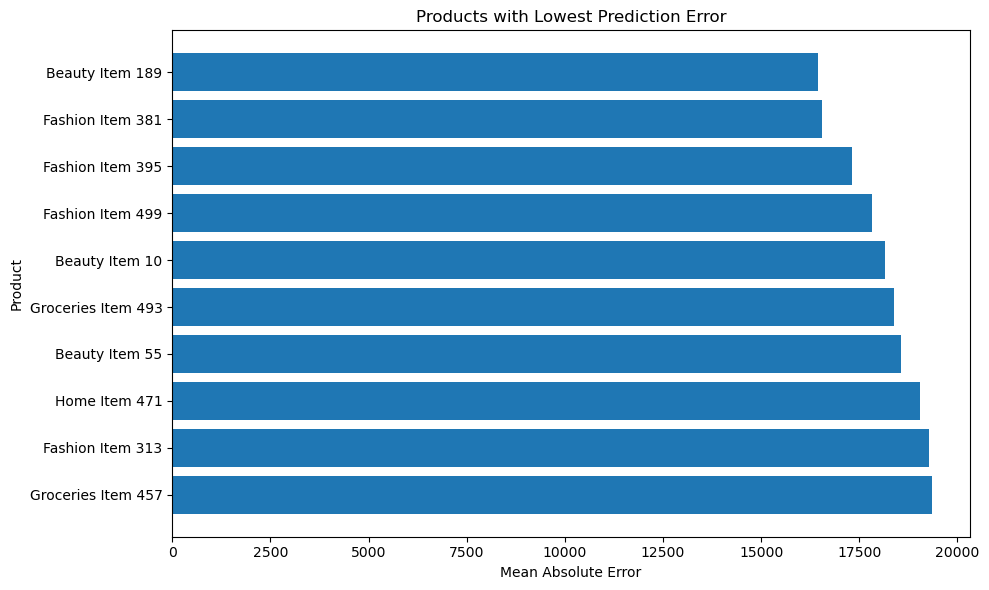

In [77]:
top_predictable_products = (
    product_prediction.head(10)
)


plt.figure(
    figsize=(10, 6)
)


plt.barh(
    top_predictable_products[
        "Product_Name"
    ],
    top_predictable_products[
        "MAE"
    ]
)


plt.xlabel(
    "Mean Absolute Error"
)

plt.ylabel(
    "Product"
)

plt.title(
    "Products with Lowest Prediction Error"
)


plt.gca().invert_yaxis()

plt.tight_layout()

plt.show()

In [78]:
segment_spending = (
    master
    .groupby(
        "Customer_Segment"
    )
    .agg(
        Total_Order_Value=(
            "Order_Total",
            "sum"
        ),

        Average_Order_Value=(
            "Order_Total",
            "mean"
        ),

        Number_of_Orders=(
            "Order_ID",
            "count"
        )
    )
    .sort_values(
        "Average_Order_Value",
        ascending=False
    )
)


display(
    segment_spending
)

,Total_Order_Value,Average_Order_Value,Number_of_Orders
Customer_Segment,,,
Silver,2592748530,154578.699696,16773
Gold,2613563934,154092.561406,16961
Bronze,2506323052,154083.551703,16266


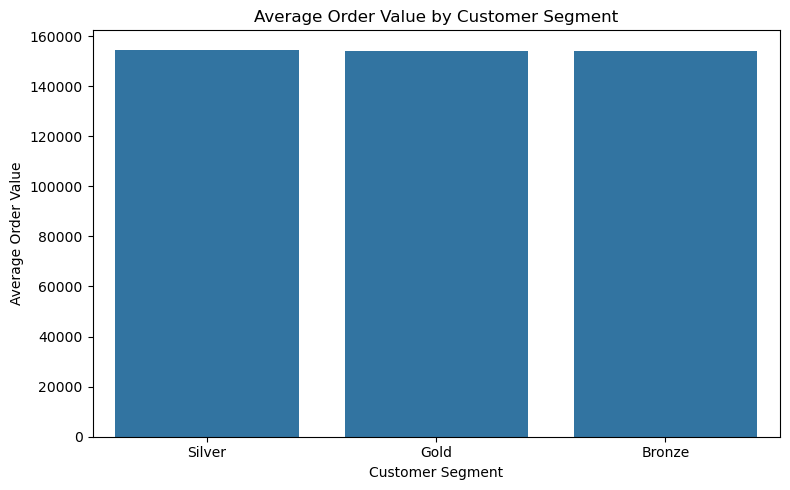

In [79]:
segment_spending_plot = (
    segment_spending
    .reset_index()
)


plt.figure(
    figsize=(8, 5)
)


sns.barplot(
    data=segment_spending_plot,
    x="Customer_Segment",
    y="Average_Order_Value"
)


plt.xlabel(
    "Customer Segment"
)

plt.ylabel(
    "Average Order Value"
)

plt.title(
    "Average Order Value by Customer Segment"
)


plt.tight_layout()

plt.show()

In [80]:
master["Age_Group"] = pd.cut(
    master["Age"],

    bins=[
        0,
        25,
        35,
        45,
        55,
        65,
        100
    ],

    labels=[
        "Under 25",
        "25-34",
        "35-44",
        "45-54",
        "55-64",
        "65+"
    ],

    right=False
)


age_spending = (
    master
    .groupby(
        "Age_Group",
        observed=False
    )
    .agg(
        Average_Order_Value=(
            "Order_Total",
            "mean"
        ),

        Total_Order_Value=(
            "Order_Total",
            "sum"
        ),

        Number_of_Orders=(
            "Order_ID",
            "count"
        )
    )
)


display(
    age_spending
)

,Average_Order_Value,Total_Order_Value,Number_of_Orders
Age_Group,,,
Under 25,152017.914231,1024448724,6739
25-34,154099.014841,1443291373,9366
35-44,153449.493782,1431376878,9328
45-54,154835.273465,1430213421,9237
55-64,156209.304773,1518666861,9722
65+,154179.432775,864638259,5608


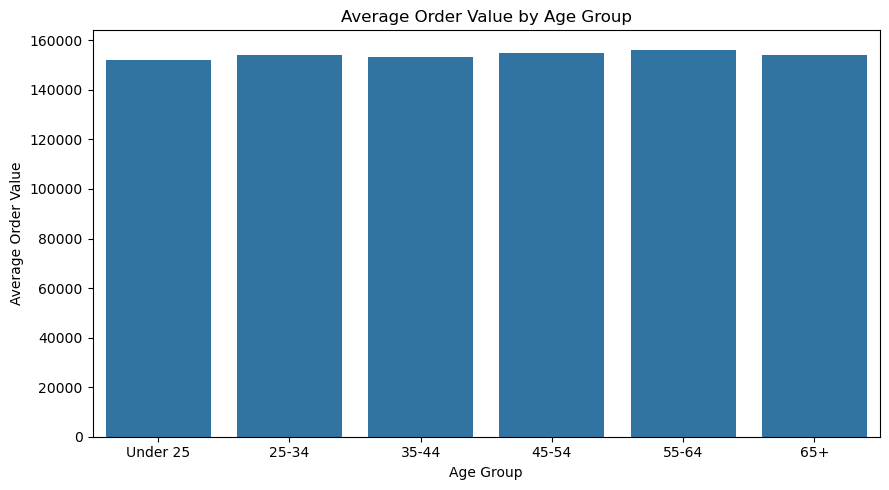

In [81]:
age_spending_plot = (
    age_spending
    .reset_index()
)


plt.figure(
    figsize=(9, 5)
)


sns.barplot(
    data=age_spending_plot,
    x="Age_Group",
    y="Average_Order_Value"
)


plt.xlabel(
    "Age Group"
)

plt.ylabel(
    "Average Order Value"
)

plt.title(
    "Average Order Value by Age Group"
)


plt.tight_layout()

plt.show()

In [82]:
store_performance = (
    master
    .groupby(
        [
            "Store_ID",
            "Store_Name",
            "Region"
        ]
    )
    .agg(
        Total_Sales=(
            "Order_Total",
            "sum"
        ),

        Average_Order_Value=(
            "Order_Total",
            "mean"
        ),

        Number_of_Orders=(
            "Order_ID",
            "count"
        ),

        Return_Rate=(
            "Return_Flag",
            "mean"
        )
    )
    .reset_index()
)


store_performance[
    "Return_Rate"
] = (
    store_performance[
        "Return_Rate"
    ] * 100
)


store_performance = (
    store_performance
    .sort_values(
        "Total_Sales",
        ascending=False
    )
)


display(
    store_performance.head(10)
)

,Store_ID,Store_Name,Region,Total_Sales,Average_Order_Value,Number_of_Orders,Return_Rate
14,STR015,ShopSmart Lagos,North,317657047,153903.608043,2064,4.021318
20,STR021,ShopSmart Lagos,West,316797164,156057.716256,2030,4.729064
16,STR017,ShopSmart Abuja,South,315281422,156700.507952,2012,4.721670
9,STR010,ShopSmart Abuja,North,314830027,153425.939084,2052,5.311891
17,STR018,ShopSmart Ibadan,East,314225962,154183.494603,2038,5.691855
7,STR008,ShopSmart Port Harcourt,North,314182938,155613.144131,2019,4.457652
11,STR012,ShopSmart Abeokuta,South,313267211,156242.998005,2005,5.735661
8,STR009,ShopSmart Ibadan,South,312943868,155307.130521,2015,4.962779
4,STR005,ShopSmart Enugu,South,311538316,153316.100394,2032,4.625984
6,STR007,ShopSmart Ibadan,North,311511328,157488.032356,1978,3.791709


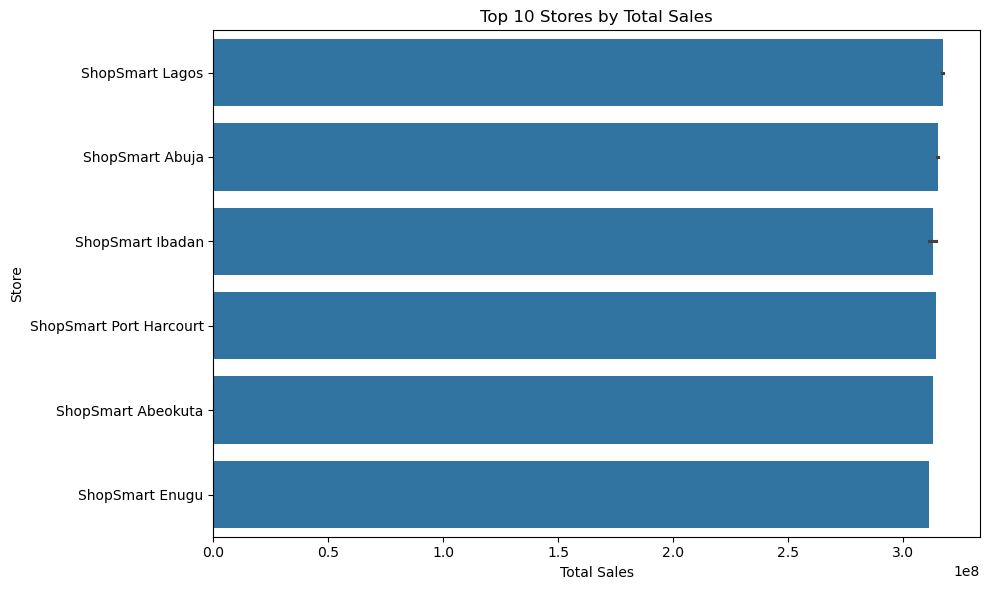

In [83]:
top_stores = (
    store_performance
    .head(10)
)


plt.figure(
    figsize=(10, 6)
)


sns.barplot(
    data=top_stores,
    y="Store_Name",
    x="Total_Sales"
)


plt.xlabel(
    "Total Sales"
)

plt.ylabel(
    "Store"
)

plt.title(
    "Top 10 Stores by Total Sales"
)


plt.tight_layout()

plt.show()

In [84]:
store_returns = (
    store_performance
    .sort_values(
        "Return_Rate",
        ascending=False
    )
)


display(
    store_returns[
        [
            "Store_ID",
            "Store_Name",
            "Number_of_Orders",
            "Return_Rate"
        ]
    ].head(10)
)

,Store_ID,Store_Name,Number_of_Orders,Return_Rate
11,STR012,ShopSmart Abeokuta,2005,5.735661
17,STR018,ShopSmart Ibadan,2038,5.691855
0,STR001,ShopSmart Abuja,1995,5.563910
24,STR025,ShopSmart Asaba,2009,5.425585
13,STR014,ShopSmart Port Harcourt,1998,5.355355
15,STR016,ShopSmart Abeokuta,1985,5.340050
2,STR003,ShopSmart Lagos,1970,5.329949
3,STR004,ShopSmart Asaba,1918,5.318040
9,STR010,ShopSmart Abuja,2052,5.311891
23,STR024,ShopSmart Ibadan,2002,5.044955


## Business Uses of the Predictive Models

The regression model can help ShopSmart understand the transaction and
customer characteristics associated with order value. The model can support
sales forecasting, customer segmentation, targeted promotions and inventory
planning.

The classification model can estimate the probability that an order will be
returned. This can help ShopSmart identify transactions with higher predicted
return risk and investigate the product, customer and operational
characteristics associated with returns.

The models should be treated as decision-support tools rather than substitutes
for managerial judgement.

## Model Limitations

1. Linear regression assumes a linear relationship between the predictors and
   the target variable.

2. Logistic regression assumes that the predictors have a linear relationship
   with the log-odds of the classification outcome.

3. Returned orders represent a relatively small proportion of transactions,
   resulting in class imbalance.

4. The available variables may not contain all the factors that influence
   customer spending and product returns.

5. Historical purchasing and return patterns may change over time.

6. Some predictor variables may be correlated.

7. Order_Total is constructed from transaction information including quantity,
   unit price, discount and shipping cost. Therefore, using these components as
   predictors can produce strong predictive performance partly because they
   mathematically determine the target.

8. The models identify predictive associations and should not be interpreted
   as proving causal relationships.

## Additional Data That Could Improve Predictions

Additional variables that could improve future models include:

- Customer purchasing history available before each order
- Previous return history
- Customer browsing behaviour
- Customer satisfaction ratings
- Product ratings and reviews
- Marketing campaign information
- Promotion information
- Delivery time
- Delivery delays
- Shipping provider information
- Product quality indicators
- Supplier-product relationships
- Holiday and seasonal indicators
- Competitor pricing
- Loyalty programme information
- Customer service interactions

In [85]:
import joblib
import os


os.makedirs(
    "models",
    exist_ok=True
)

In [86]:
joblib.dump(
    linear_model,
    "models/linear_regression.pkl"
)


joblib.dump(
    logistic_model,
    "models/logistic_regression.pkl"
)


print(
    "Linear and Logistic Regression models saved."
)

Linear and Logistic Regression models saved.


In [87]:
reg_scaler = (
    linear_model
    .named_steps["preprocessor"]
    .named_transformers_["num"]
)


reg_encoder = (
    linear_model
    .named_steps["preprocessor"]
    .named_transformers_["cat"]
)


joblib.dump(
    reg_scaler,
    "models/scaler.pkl"
)


joblib.dump(
    reg_encoder,
    "models/encoder.pkl"
)


print(
    "Scaler and encoder saved successfully."
)

Scaler and encoder saved successfully.


In [88]:
print(
    "Saved model files:"
)

for file in os.listdir(
    "models"
):
    print(file)

Saved model files:
encoder.pkl
linear_regression.pkl
logistic_regression.pkl
scaler.pkl


In [89]:
loaded_linear_model = joblib.load(
    "models/linear_regression.pkl"
)


loaded_logistic_model = joblib.load(
    "models/logistic_regression.pkl"
)


print(
    "Saved models loaded successfully."
)

Saved models loaded successfully.


In [90]:
sample_regression = (
    X_test_reg.iloc[[0]]
)


predicted_value = (
    loaded_linear_model
    .predict(
        sample_regression
    )[0]
)


actual_value = (
    y_test_reg.iloc[0]
)


print(
    f"Predicted Order Value: {predicted_value:,.2f}"
)

print(
    f"Actual Order Value: {actual_value:,.2f}"
)

Predicted Order Value: 180,292.83
Actual Order Value: 166,896.00


In [91]:
sample_classification = (
    X_test_class.iloc[[0]]
)


predicted_return = (
    loaded_logistic_model
    .predict(
        sample_classification
    )[0]
)


predicted_probability = (
    loaded_logistic_model
    .predict_proba(
        sample_classification
    )[0, 1]
)


actual_return = (
    y_test_class.iloc[0]
)


print(
    "Predicted Return Flag:",
    predicted_return
)

print(
    f"Return Probability: {predicted_probability:.2%}"
)

print(
    "Actual Return Flag:",
    actual_return
)

Predicted Return Flag: 0
Return Probability: 33.15%
Actual Return Flag: 0


In [92]:
# ============================================================
# SAVE TRAIN AND TEST DATASETS
# ============================================================

train_data, test_data = train_test_split(
    master,
    test_size=0.20,
    random_state=42,
    stratify=master["Return_Flag"]
)


train_data.to_csv(
    "data/train.csv",
    index=False
)


test_data.to_csv(
    "data/test.csv",
    index=False
)


print(
    "Training dataset:",
    train_data.shape
)

print(
    "Testing dataset:",
    test_data.shape
)


print(
    "\nTraining return rate:",
    f"{train_data['Return_Flag'].mean():.2%}"
)

print(
    "Testing return rate:",
    f"{test_data['Return_Flag'].mean():.2%}"
)

Training dataset: (40000, 51)
Testing dataset: (10000, 51)

Training return rate: 4.88%
Testing return rate: 4.88%


In [93]:
print("=" * 65)
print("SHOPSMART MACHINE LEARNING PROJECT - FINAL CHECK")
print("=" * 65)

print(
    f"Master dataset rows: {len(master):,}"
)

print(
    f"Unique orders: {master['Order_ID'].nunique():,}"
)

print(
    f"Training rows: {len(train_data):,}"
)

print(
    f"Testing rows: {len(test_data):,}"
)

print(
    f"\nRegression MAE: {mae:,.2f}"
)

print(
    f"Regression RMSE: {rmse:,.2f}"
)

print(
    f"Regression R²: {r2:.4f}"
)

print(
    f"\nClassification Accuracy: {accuracy:.4f}"
)

print(
    f"Classification Precision: {precision:.4f}"
)

print(
    f"Classification Recall: {recall:.4f}"
)

print(
    f"Classification F1 Score: {f1:.4f}"
)

print("\nSaved data files:")
print(" - data/master_dataset.csv")
print(" - data/train.csv")
print(" - data/test.csv")

print("\nSaved models:")
print(" - models/linear_regression.pkl")
print(" - models/logistic_regression.pkl")
print(" - models/scaler.pkl")
print(" - models/encoder.pkl")

print("\n" + "=" * 65)
print("PROJECT COMPLETED SUCCESSFULLY")
print("=" * 65)

SHOPSMART MACHINE LEARNING PROJECT - FINAL CHECK
Master dataset rows: 50,000
Unique orders: 50,000
Training rows: 40,000
Testing rows: 10,000

Regression MAE: 31,010.22
Regression RMSE: 41,268.26
Regression R²: 0.8830

Classification Accuracy: 0.5430
Classification Precision: 0.0475
Classification Recall: 0.4385
Classification F1 Score: 0.0856

Saved data files:
 - data/master_dataset.csv
 - data/train.csv
 - data/test.csv

Saved models:
 - models/linear_regression.pkl
 - models/logistic_regression.pkl
 - models/scaler.pkl
 - models/encoder.pkl

PROJECT COMPLETED SUCCESSFULLY
